# 10-4. CRPS 방식 비교 (auto_arima / 원·로그 스케일 / 자체·리샘플링)

auto_arima 4개 조합(스케일 2 x 구간 2)의 CRPS를 기존 `crps7`과 통일 방식(`crps_ensemble`)으로 계산해 비교한다.
- 통일 방식의 앙상블: 리샘플링은 오차 표본 500개, 자체는 정규 분위수 500개(로그는 `exp`로 변환)

- 모든 CRPS는 원 스케일에서 `var_std`로 나누고 88개(22 origin x h=1~4)를 평균한다.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
from arch.univariate import ARX, ZeroMean, GARCH
from scipy import stats

H, MIN_TRAIN, INITIAL_CALIB, ALPHA = 4, 20, 15, 0.10
Z = stats.norm.ppf(1 - ALPHA / 2)
D, N_RESAMPLE, P_MAX, SCALE = 1, 500, 3, 100.0

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
data = raw[["quarter", "X3_l1"]].dropna().reset_index(drop=True)
quarters, vals = data["quarter"].values, data["X3_l1"].values.astype(float)
LOG = SCALE * np.log(vals)
var_std = vals.std()
origins = list(range(MIN_TRAIN, len(vals) - H + 1))
scored_origins = origins[INITIAL_CALIB:]
FIRST = scored_origins[0]
LEVELS = np.array([0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9])


def label(o):
    return f"origin {o} (훈련 {quarters[0]}~{quarters[o - 1]}, 예측 {quarters[o]}~{quarters[o + H - 1]})"


def pinball(q, y, tau):
    return np.where(y >= q, (y - q) * tau, (q - y) * (1 - tau))


def crps7(q7, y):
    return 2 * np.mean([pinball(q7[k], y, LEVELS[k]) for k in range(7)]) / var_std


def to_orig(x):
    return np.exp(np.asarray(x) / SCALE)


def difference(values, d):
    x = np.asarray(values, dtype=float)
    hist = []
    for _ in range(d):
        hist.append(x.copy())
        x = np.diff(x)
    return x, hist


def undiff_mean(diff_fc, hist, d):
    fc = np.asarray(diff_fc, dtype=float)
    for i in reversed(range(d)):
        fc = hist[i][-1] + np.cumsum(fc)
    return fc


def level_sigma(ar_coefs, d, innov_var):
    p = len(ar_coefs)
    psi = np.zeros(H)
    for j in range(H):
        psi[j] = 1.0 if j == 0 else sum(ar_coefs[k] * psi[j - 1 - k] for k in range(min(p, j)))
    for _ in range(d):
        psi = np.cumsum(psi)
    return np.sqrt(np.array([sum(psi[h - i] ** 2 * innov_var[i] for i in range(h + 1)) for h in range(H)]))


def select_p(train):
    # AR단독 auto_arima(정확우도, AICc): d=1 고정, MA 없음, 절편 없음 -> GARCH의 AR 차수로 사용
    m = pm.auto_arima(train, d=D, seasonal=False, start_q=0, max_q=0, max_p=P_MAX, information_criterion="aicc",
                      with_intercept=False, suppress_warnings=True, error_action="ignore")
    return m.order[0], m


def ar_fallback(m):
    fc, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    return np.asarray(fc), (conf[:, 1] - conf[:, 0]) / (2 * Z)


def garch_forecast(train, p):
    diff_train, hist = difference(train, D)
    am = ZeroMean(diff_train, rescale=False) if p == 0 else ARX(diff_train, lags=p, constant=False, rescale=False)
    am.volatility = GARCH(p=1, q=1)
    res = am.fit(disp="off")
    f = res.forecast(horizon=H, reindex=False)
    ar = [res.params[f"y[{k}]"] for k in range(1, p + 1)]
    fc = undiff_mean(f.mean.values[-1], hist, D)
    sig = level_sigma(ar, D, f.residual_variance.values[-1])
    if not (np.all(np.isfinite(fc)) and np.all(np.isfinite(sig))):
        raise ValueError("non-finite forecast")
    return fc, sig


def model_forecast(series):
    # AR 차수 p는 AR단독 auto_arima가 선택, 적합 실패 시 AR단독 예측으로 대체(대체 횟수는 기록)
    p, m = select_p(series)
    try:
        fc, sig = garch_forecast(series, p)
        return fc, sig, "GARCH", p
    except Exception:
        fc, sig = ar_fallback(m)
        return fc, sig, "AR대체", p


def rng_for(name):
    return np.random.default_rng(int.from_bytes(name.encode(), "little") % (2 ** 32))


def model_forecast(series):
    # auto_arima(d=1, AICc, q 허용): 9-3/9-4와 같은 모델. 자체 σ_h는 90% conf_int에서 역산
    m = pm.auto_arima(series, d=D, seasonal=False, information_criterion="aicc", suppress_warnings=True, error_action="ignore")
    fc = np.asarray(m.predict(n_periods=H))
    _, c90 = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    return fc, (c90[:, 1] - c90[:, 0]) / (2 * Z), "auto_arima", None

std = False
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
N_ENS = 500
U = stats.norm.ppf((np.arange(N_ENS) + 0.5) / N_ENS)      # 표준정규 분위수 N개 (난수 없음)
print(f"채점 origin {len(scored_origins)}개, var_std = {var_std:.3f}")

채점 origin 22개, var_std = 282.627


## 1. 계산

같은 코드·시드로 표본을 다시 만들고, 기존 결과와 같은 값인지 검증한다.

In [2]:
CACHE = "../cache/cache_104_crps_compare_df.pkl"


def run(logmode):
    seed = "X3_l1_9-4_log_resample_vs_self" if logmode else "X3_l1_9-3_resample_vs_self"
    rng = rng_for(seed)
    tf = to_orig if logmode else (lambda x: x)
    pool = {h: np.array([]) for h in range(1, H + 1)}
    rows = []
    for oi, o in enumerate(origins):
        train, actual = (LOG[:o] if logmode else vals[:o]), vals[o:o + H]
        fc, sig, src, p = model_forecast(train)
        if oi >= INITIAL_CALIB:
            for h in range(1, H + 1):
                a = actual[h - 1]
                s_h = max(sig[h - 1], 1e-6)
                scale = s_h if std else 1.0
                samples = fc[h - 1] + scale * rng.choice(pool[h] - np.median(pool[h]), size=N_RESAMPLE, replace=True)
                q7_res = tf(np.quantile(samples, LEVELS))
                q7_self = tf(fc[h - 1] + s_h * stats.norm.ppf(LEVELS))
                base = {"스케일": "로그" if logmode else "원", "origin": o, "h": h}
                rows.append({**base, "구간": "리샘플링", "crps7": crps7(q7_res, a), "통일(앙상블)": ps.crps_ensemble(a, tf(samples)) / var_std,
                             "정확값(가우시안)": np.nan})
                rows.append({**base, "구간": "자체", "crps7": crps7(q7_self, a), "통일(앙상블)": ps.crps_ensemble(a, tf(fc[h - 1] + s_h * U)) / var_std,
                             "정확값(가우시안)": np.nan if logmode else ps.crps_gaussian(a, mu=fc[h - 1], sig=s_h) / var_std})
        for h in range(1, H + 1):
            e = (np.log(actual[h - 1]) * SCALE if logmode else actual[h - 1]) - fc[h - 1]
            pool[h] = np.append(pool[h], e / max(sig[h - 1], 1e-6) if std else e)
    return pd.DataFrame(rows)


if os.path.exists(CACHE):
    res = pd.read_pickle(CACHE)
    print("캐시에서 로드:", len(res), "행")
else:
    res = pd.concat([run(False), run(True)], ignore_index=True)
    res.to_pickle(CACHE)
    print("계산 완료:", len(res), "행")

for sc, f in [("원", "cache_93_resample_vs_self_df"), ("로그", "cache_94_log_resample_vs_self_df")]:
    old = pd.read_pickle(f"../cache/{f}.pkl")
    for name in ["리샘플링", "자체"]:
        a = res[(res["스케일"] == sc) & (res["구간"] == name)].sort_values(["origin", "h"])["crps7"].values
        b = old[old["방식"] == name].sort_values(["origin", "h"])["CRPS(7분위)"].values
        print(f"{sc} / {name}: 기존 캐시와 최대 차이 {np.abs(a - b).max():.2e}")

캐시에서 로드: 352 행
원 / 리샘플링: 기존 캐시와 최대 차이 0.00e+00
원 / 자체: 기존 캐시와 최대 차이 8.88e-16
로그 / 리샘플링: 기존 캐시와 최대 차이 0.00e+00
로그 / 자체: 기존 캐시와 최대 차이 1.61e-15


## 2. 4개 조합의 평균 CRPS

`crps7 차이`는 통일 방식 대비 차이다.

In [3]:
per = res.groupby(["스케일", "구간", "origin", "h"])[["crps7", "통일(앙상블)"]].mean().groupby(["스케일", "구간", "origin"]).mean()
tab = per.groupby(["스케일", "구간"]).mean().loc[[("원", "리샘플링"), ("원", "자체"), ("로그", "리샘플링"), ("로그", "자체")]]
tab["crps7 차이(%)"] = 100 * (tab["crps7"] / tab["통일(앙상블)"] - 1)
tab["순위(crps7)"] = tab["crps7"].rank().astype(int)
tab["순위(통일)"] = tab["통일(앙상블)"].rank().astype(int)
display(tab.round(4))
g = res[(res["스케일"] == "원") & (res["구간"] == "자체")]
print("검증: 원 스케일 자체에서 통일(앙상블)과 정확값(가우시안)의 최대 차이(88개):", float(np.abs(g["통일(앙상블)"] - g["정확값(가우시안)"]).max()))

crps7  통일(앙상블)  crps7 차이(%)  순위(crps7)  순위(통일)
스케일 구간                                                   
원   리샘플링  0.5985   0.5904       1.3593          1       1
    자체    0.6210   0.6104       1.7413          2       2
로그  리샘플링  0.8408   0.8151       3.1549          4       4
    자체    0.7666   0.7493       2.2998          3       3

검증: 원 스케일 자체에서 통일(앙상블)과 정확값(가우시안)의 최대 차이(88개): 0.0002456558641386053


## 3. 자체 vs 리샘플링 -- 우열이 바뀌는가

In [4]:
rows = []
for sc in ["원", "로그"]:
    pc = per.loc[sc].reset_index().pivot(index="origin", columns="구간", values=["crps7", "통일(앙상블)"])
    for m in ["crps7", "통일(앙상블)"]:
        d = pc[m]["리샘플링"] - pc[m]["자체"]
        rows.append({"스케일": sc, "방식": m, "리샘플링 평균": pc[m]["리샘플링"].mean(), "자체 평균": pc[m]["자체"].mean(),
                     "평균 차이(리샘플링-자체)": d.mean(), "리샘플링이 앞선 origin": int((d < 0).sum())})
display(pd.DataFrame(rows).set_index(["스케일", "방식"]).round(4))

리샘플링 평균   자체 평균  평균 차이(리샘플링-자체)  리샘플링이 앞선 origin
스케일 방식                                                       
원   crps7     0.5985  0.6210         -0.0226               12
    통일(앙상블)   0.5904  0.6104         -0.0200               12
로그  crps7     0.8408  0.7666          0.0742                7
    통일(앙상블)   0.8151  0.7493          0.0657                7

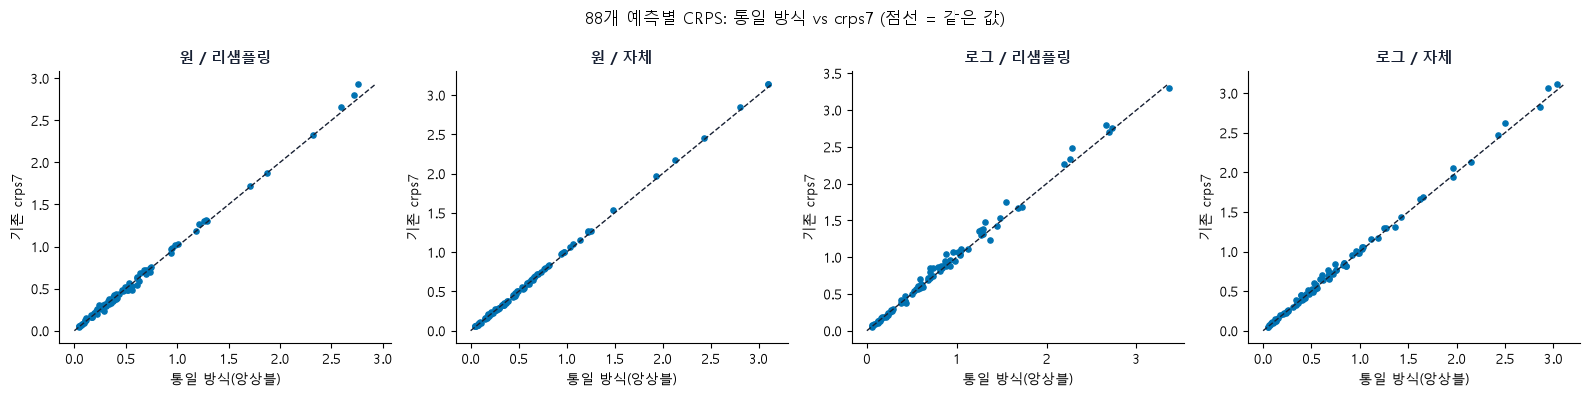

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, ((sc, nm), g) in zip(axes, res.groupby(["스케일", "구간"], sort=False)):
    ax.scatter(g["통일(앙상블)"], g["crps7"], s=14, color="#0072B2")
    m = max(g["통일(앙상블)"].max(), g["crps7"].max())
    ax.plot([0, m], [0, m], color="#172033", linestyle="--", linewidth=1)
    ax.set_title(f"{sc} / {nm}", fontsize=11, fontweight="bold", color="#172033")
    ax.set_xlabel("통일 방식(앙상블)")
    ax.set_ylabel("기존 crps7")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.suptitle("88개 예측별 CRPS: 통일 방식 vs crps7 (점선 = 같은 값)", fontsize=12)
fig.tight_layout()
plt.show()

## 4. 결론

**auto_arima: 두 방식의 순위가 같고, 원 스케일은 리샘플링이, 로그 스케일은 자체가 낫다.**

| 조합 | crps7 | 통일(앙상블) | crps7 차이 | 순위 |
|---|---|---|---|---|
| 원 / 리샘플링 | 0.5985 | 0.5904 | +1.4% | 1 |
| 원 / 자체 | 0.6210 | 0.6104 | +1.7% | 2 |
| 로그 / 자체 | 0.7666 | 0.7493 | +2.3% | 3 |
| 로그 / 리샘플링 | 0.8408 | 0.8151 | +3.2% | 4 |

- 기존 결과와 같은 값으로 재현했고, 리샘플링이 앞선 origin 수도 같다(원 12개, 로그 7개).
- `crps7` 차이는 세 모델 중 가장 작다(+1.4~3.2%).
- 한계: 22개 origin이 겹치며 유의성 검정은 하지 않았다.